## Problem Statement

You need to build a model that is able to classify customer complaints based on the products/services. By doing so, you can segregate these tickets into their relevant categories and, therefore, help in the quick resolution of the issue.

You will be doing topic modelling on the <b>.json</b> data provided by the company. Since this data is not labelled, you need to apply NMF to analyse patterns and classify tickets into the following five clusters based on their products/services:

* Credit card / Prepaid card

* Bank account services

* Theft/Dispute reporting

* Mortgages/loans

* Others


With the help of topic modelling, you will be able to map each ticket onto its respective department/category. You can then use this data to train any supervised model such as logistic regression, decision tree or random forest. Using this trained model, you can classify any new customer complaint support ticket into its relevant department.

## Pipelines that needs to be performed:

You need to perform the following eight major tasks to complete the assignment:

1.  Data loading

2. Text preprocessing

3. Exploratory data analysis (EDA)

4. Feature extraction

5. Topic modelling

6. Model building using supervised learning

7. Model training and evaluation

8. Model inference

## Importing the necessary libraries

In [1]:
import json
import numpy as np
import pandas as pd
import re, nltk, spacy, string
import en_core_web_sm
nlp = en_core_web_sm.load()
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from plotly.offline import plot
import plotly.graph_objects as go
import plotly.express as px

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from pprint import pprint

nltk.download('stopwords')
nltk.download('punkt')

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/I072374/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /Users/I072374/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

## Loading the data

The data is in JSON format and we need to convert it to a dataframe.

In [2]:
# Opening JSON file
f = open('complaints-2021-05-14_08_16.json')  # Update path to your data file if needed

# returns JSON object as a dictionary
data = json.load(f)
df = pd.json_normalize(data)

## Data preparation

In [3]:
# Inspect the dataframe to understand the given data.
print(df.head())
print(df.shape)
print(df.size)


                _index      _type      _id  _score   _source.tags  \
0  complaint-public-v2  complaint  3211475     0.0            NaN   
1  complaint-public-v2  complaint  3229299     0.0  Servicemember   
2  complaint-public-v2  complaint  3199379     0.0            NaN   
3  complaint-public-v2  complaint  2673060     0.0            NaN   
4  complaint-public-v2  complaint  3203545     0.0            NaN   

  _source.zip_code _source.complaint_id                       _source.issue  \
0            90301              3211475   Attempts to collect debt not owed   
1            319XX              3229299     Written notification about debt   
2            77069              3199379  Other features, terms, or problems   
3            48066              2673060      Trouble during payment process   
4            10473              3203545                    Fees or interest   

       _source.date_received _source.state  ... _source.company_response  \
0  2019-04-13T12:00:00-05:00      

In [4]:
#print the column names
print(df.columns.tolist())

['_index', '_type', '_id', '_score', '_source.tags', '_source.zip_code', '_source.complaint_id', '_source.issue', '_source.date_received', '_source.state', '_source.consumer_disputed', '_source.product', '_source.company_response', '_source.company', '_source.submitted_via', '_source.date_sent_to_company', '_source.company_public_response', '_source.sub_product', '_source.timely', '_source.complaint_what_happened', '_source.sub_issue', '_source.consumer_consent_provided']


In [5]:
#Assign new column names
df.columns = [col.split('.')[-1] for col in df.columns]
print(df.columns.tolist())

['_index', '_type', '_id', '_score', 'tags', 'zip_code', 'complaint_id', 'issue', 'date_received', 'state', 'consumer_disputed', 'product', 'company_response', 'company', 'submitted_via', 'date_sent_to_company', 'company_public_response', 'sub_product', 'timely', 'complaint_what_happened', 'sub_issue', 'consumer_consent_provided']


In [6]:
#Assign nan in place of blanks in the complaints column
df['complaint_what_happened'] = df['complaint_what_happened'].replace('', np.nan)
print(f"Null values are: {df['complaint_what_happened'].isnull().sum()}")

Null values are: 57241


In [7]:
#Remove all rows where complaints column is nan
df =df.dropna(subset=["complaint_what_happened"])
df = df.reset_index(drop=True)
df.shape

(21072, 22)

## Prepare the text for topic modeling

Once you have removed all the blank complaints, you need to:

* Make the text lowercase
* Remove text in square brackets
* Remove punctuation
* Remove words containing numbers


Once you have done these cleaning operations you need to perform the following:
* Lemmatize the texts
* Extract the POS tags of the lemmatized text and remove all the words which have tags other than NN[tag == "NN"].


In [8]:
# Write your function here to clean the text and remove all the unnecessary elements.
def clean_text(text):
    #Make lower case, Remove text in square bracket,s remove punctuation, remove words containing number
    text = text.lower()
    text = re.sub(r'\[.*?\]', '', text)
    text = re.sub(r'[%s]' % re.escape(string.punctuation), '' , text)
    text = re.sub(r'\w*\d\w*','', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

In [9]:
#Write your function to Lemmatize the texts
def lemmatize_text(text):
    doc = nlp(text)
    return ' '.join([token.lemma_ for token in doc])

In [10]:
#Create a dataframe('df_clean') that will have only the complaints and the lemmatized complaints
df_clean = df[['complaint_what_happened']].copy()
df_clean['complaints_clean'] = df_clean['complaint_what_happened'].apply(clean_text)
df_clean['complaint_lemmantized'] = df_clean['complaint_what_happened'].apply(lemmatize_text)

In [11]:
df_clean

,complaint_what_happened,complaints_clean,complaint_lemmantized
0,Good morning my name is XXXX XXXX and I apprec...,good morning my name is xxxx xxxx and i apprec...,good morning my name be XXXX xxxx and I apprec...
1,I upgraded my XXXX XXXX card in XX/XX/2018 and...,i upgraded my xxxx xxxx card in and was told b...,I upgrade my XXXX XXXX card in XX / XX/2018 an...
2,Chase Card was reported on XX/XX/2019. However...,chase card was reported on however fraudulent ...,Chase Card be report on XX / XX/2019 . however...
3,"On XX/XX/2018, while trying to book a XXXX XX...",on while trying to book a xxxx xxxx ticket i c...,"on XX / XX/2018 , while try to book a XXXX x..."
4,my grand son give me check for {$1600.00} i de...,my grand son give me check for i deposit it in...,my grand son give I check for { $ 1600.00 } I ...
...,...,...,...
21067,After being a Chase Card customer for well ove...,after being a chase card customer for well ove...,after be a Chase Card customer for well over a...
21068,"On Wednesday, XX/XX/XXXX I called Chas, my XXX...",on wednesday xxxxxxxx i called chas my xxxx xx...,"on Wednesday , XX / XX / XXXX I call Chas , my..."
21069,I am not familiar with XXXX pay and did not un...,i am not familiar with xxxx pay and did not un...,I be not familiar with XXXX pay and do not und...
21070,I have had flawless credit for 30 yrs. I've ha...,i have had flawless credit for yrs ive had cha...,I have have flawless credit for 30 yr . I have...


In [12]:
#Write your function to extract the POS tags

def pos_tag(text):
  # write your code here
  doc = nlp(text)
  return ' '.join([token.text for token in doc if token.tag_ == 'NN'])



df_clean["complaint_POS_removed"] =  df_clean["complaint_lemmantized"].apply(pos_tag) #this column should contain lemmatized text with all the words removed which have tags other than NN[tag == "NN"].


In [13]:
#The clean dataframe should now contain the raw complaint, lemmatized complaint and the complaint after removing POS tags.
df_clean

,complaint_what_happened,complaints_clean,complaint_lemmantized,complaint_POS_removed
0,Good morning my name is XXXX XXXX and I apprec...,good morning my name is xxxx xxxx and i apprec...,good morning my name be XXXX xxxx and I apprec...,morning name stop cardmember service debt veri...
1,I upgraded my XXXX XXXX card in XX/XX/2018 and...,i upgraded my xxxx xxxx card in and was told b...,I upgrade my XXXX XXXX card in XX / XX/2018 an...,XXXX card XX/2018 agent anniversary date agent...
2,Chase Card was reported on XX/XX/2019. However...,chase card was reported on however fraudulent ...,Chase Card be report on XX / XX/2019 . however...,report application identity consent service cr...
3,"On XX/XX/2018, while trying to book a XXXX XX...",on while trying to book a xxxx xxxx ticket i c...,"on XX / XX/2018 , while try to book a XXXX x...",ticket offer ticket reward card information of...
4,my grand son give me check for {$1600.00} i de...,my grand son give me check for i deposit it in...,my grand son give I check for { $ 1600.00 } I ...,son chase account fund chase bank account mone...
...,...,...,...,...
21067,After being a Chase Card customer for well ove...,after being a chase card customer for well ove...,after be a Chase Card customer for well over a...,customer decade solicitation credit card bonus...
21068,"On Wednesday, XX/XX/XXXX I called Chas, my XXX...",on wednesday xxxxxxxx i called chas my xxxx xx...,"on Wednesday , XX / XX / XXXX I call Chas , my...",provider claim purchase protection benefit XXX...
21069,I am not familiar with XXXX pay and did not un...,i am not familiar with xxxx pay and did not un...,I be not familiar with XXXX pay and do not und...,risk consumer bank app year banking merchant m...
21070,I have had flawless credit for 30 yrs. I've ha...,i have had flawless credit for yrs ive had cha...,I have have flawless credit for 30 yr . I have...,credit yr credit card problem balance transfer...


## Exploratory data analysis to get familiar with the data.

Write the code in this task to perform the following:

*   Visualise the data according to the 'Complaint' character length
*   Using a word cloud find the top 40 words by frequency among all the articles after processing the text
*   Find the top unigrams,bigrams and trigrams by frequency among all the complaints after processing the text. ‘




In [14]:
# Write your code here to visualise the data according to the 'Complaint' character length
df_clean['complaint_length'] = df_clean['complaint_what_happened'].apply(len)
fig = px.histogram(df_clean, x='complaint_length', nbins=50, title='Distribution of Complaint Character Length', labels ={'complaint_length' :'Character Length'} )

fig.show()

#### Find the top 40 words by frequency among all the articles after processing the text.

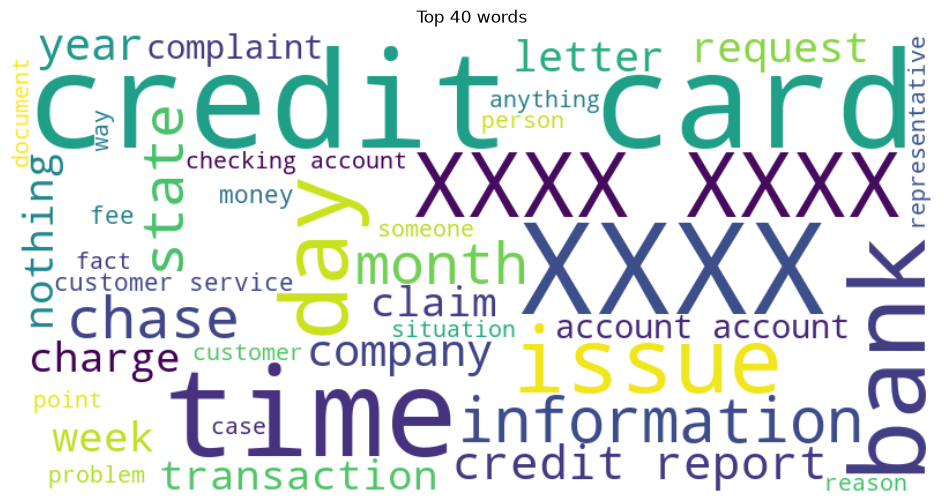

In [15]:
#Using a word cloud find the top 40 words by frequency among all the articles after processing the text
from wordcloud import WordCloud

all_text = ' '.join(df_clean['complaint_POS_removed'].dropna())
wordcloud = WordCloud(max_words=40, background_color='white', width =800, height = 400).generate(all_text)

plt.figure(figsize = (12,6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Top 40 words')
plt.show()


In [16]:
#Removing -PRON- from the text corpus
df_clean['Complaint_clean'] = df_clean['complaint_POS_removed'].str.replace('-PRON-', '')

#### Find the top unigrams,bigrams and trigrams by frequency among all the complaints after processing the text.

In [17]:
#Write your code here to find the top 30 unigram frequency among the complaints in the cleaned datafram(df_clean).
from collections import Counter

unigram_vec = CountVectorizer(ngram_range=(1,1), max_features=30)
unigram_matrix = unigram_vec.fit_transform(df_clean['complaint_POS_removed'].dropna())
unigram_freq = dict(zip(unigram_vec.get_feature_names_out(), unigram_matrix.toarray().sum(axis=0)))
unigram_df = pd.DataFrame(sorted(unigram_freq.items(), key = lambda x: x[1], reverse=True), columns=  ['word', 'frequency'])

fig = px.bar(unigram_df, x ='word', y='frequency', title = 'Top 30 unigrams')
fig.show()

In [18]:
#Print the top 10 words in the unigram frequency
print(unigram_df.head(10).to_string(index=False))

   word  frequency
account      46941
   xxxx      30805
 credit      30400
   card      28024
payment      20908
   bank      17614
   time      16066
 charge      14760
    day      13168
  money      11924


In [19]:
#Write your code here to find the top 30 bigram frequency among the complaints in the cleaned datafram(df_clean).
bigram_vec = CountVectorizer(ngram_range=(2,2), max_features=30)
bigram_matrix = bigram_vec.fit_transform(df_clean['complaint_POS_removed'].dropna())
bigram_freq = dict(zip(bigram_vec.get_feature_names_out(), bigram_matrix.toarray().sum(axis=0)))
bigram_df = pd.DataFrame(sorted(bigram_freq.items(), key = lambda x: x[1], reverse=True), columns=  ['bigram', 'frequency'])

fig = px.bar(bigram_df, x ='bigram', y='frequency', title = 'Top 30 Bigrams')
fig.show()

In [20]:
#Print the top 10 words in the bigram frequency
print(bigram_df.head(10).to_string(index=False))

          bigram  frequency
     credit card      11285
       xxxx xxxx       4673
   credit report       3744
customer service       2624
 account account       2622
checking account       2547
    bank account       2269
      debit card       1855
      phone call       1653
    credit score       1649


In [21]:
#Write your code here to find the top 30 trigram frequency among the complaints in the cleaned datafram(df_clean).
trigram_vec = CountVectorizer(ngram_range=(3,3), max_features=30)
trigram_matrix = trigram_vec.fit_transform(df_clean['complaint_POS_removed'].dropna())
trigram_freq = dict(zip(trigram_vec.get_feature_names_out(), trigram_matrix.toarray().sum(axis=0)))
trigram_df = pd.DataFrame(sorted(trigram_freq.items(), key = lambda x: x[1], reverse=True), columns=  ['trigram', 'frequency'])

fig = px.bar(trigram_df, x ='trigram', y='frequency', title = 'Top 30 Trigrams')
fig.show()

In [22]:
#Print the top 10 words in the trigram frequency
print(trigram_df.head(10).to_string(index=False))

                        trigram  frequency
                 xxxx xxxx xxxx       1344
            credit card account       1033
            credit card company        885
          inquiry credit report        497
             credit card credit        489
            account credit card        466
             charge credit card        456
               card credit card        406
customer service representative        316
               xxxx credit card        315


## The personal details of customer has been masked in the dataset with xxxx. Let's remove the masked text as this will be of no use for our analysis

In [23]:
df_clean['Complaint_clean'] = df_clean['Complaint_clean'].str.replace('xxxx','')

In [24]:
#All masked texts has been removed
df_clean

,complaint_what_happened,complaints_clean,complaint_lemmantized,complaint_POS_removed,complaint_length,Complaint_clean
0,Good morning my name is XXXX XXXX and I apprec...,good morning my name is xxxx xxxx and i apprec...,good morning my name be XXXX xxxx and I apprec...,morning name stop cardmember service debt veri...,486,morning name stop cardmember service debt veri...
1,I upgraded my XXXX XXXX card in XX/XX/2018 and...,i upgraded my xxxx xxxx card in and was told b...,I upgrade my XXXX XXXX card in XX / XX/2018 an...,XXXX card XX/2018 agent anniversary date agent...,355,XXXX card XX/2018 agent anniversary date agent...
2,Chase Card was reported on XX/XX/2019. However...,chase card was reported on however fraudulent ...,Chase Card be report on XX / XX/2019 . however...,report application identity consent service cr...,224,report application identity consent service cr...
3,"On XX/XX/2018, while trying to book a XXXX XX...",on while trying to book a xxxx xxxx ticket i c...,"on XX / XX/2018 , while try to book a XXXX x...",ticket offer ticket reward card information of...,1502,ticket offer ticket reward card information of...
4,my grand son give me check for {$1600.00} i de...,my grand son give me check for i deposit it in...,my grand son give I check for { $ 1600.00 } I ...,son chase account fund chase bank account mone...,477,son chase account fund chase bank account mone...
...,...,...,...,...,...,...
21067,After being a Chase Card customer for well ove...,after being a chase card customer for well ove...,after be a Chase Card customer for well over a...,customer decade solicitation credit card bonus...,679,customer decade solicitation credit card bonus...
21068,"On Wednesday, XX/XX/XXXX I called Chas, my XXX...",on wednesday xxxxxxxx i called chas my xxxx xx...,"on Wednesday , XX / XX / XXXX I call Chas , my...",provider claim purchase protection benefit XXX...,2114,provider claim purchase protection benefit XXX...
21069,I am not familiar with XXXX pay and did not un...,i am not familiar with xxxx pay and did not un...,I be not familiar with XXXX pay and do not und...,risk consumer bank app year banking merchant m...,2319,risk consumer bank app year banking merchant m...
21070,I have had flawless credit for 30 yrs. I've ha...,i have had flawless credit for yrs ive had cha...,I have have flawless credit for 30 yr . I have...,credit yr credit card problem balance transfer...,2171,credit yr credit card problem balance transfer...


## Feature Extraction
Convert the raw texts to a matrix of TF-IDF features

**max_df** is used for removing terms that appear too frequently, also known as "corpus-specific stop words"
max_df = 0.95 means "ignore terms that appear in more than 95% of the complaints"

**min_df** is used for removing terms that appear too infrequently
min_df = 2 means "ignore terms that appear in less than 2 complaints"

In [25]:
#Write your code here to initialise the TfidfVectorizer
tfidf = TfidfVectorizer(max_df= 0.95, min_df = 2, stop_words = 'english')


#### Create a document term matrix using fit_transform

The contents of a document term matrix are tuples of (complaint_id,token_id) tf-idf score:
The tuples that are not there have a tf-idf score of 0

In [26]:
#Write your code here to create the Document Term Matrix by transforming the complaints column present in df_clean.
dtm = tfidf.fit_transform(df_clean['Complaint_clean'].fillna(''))
dtm.shape

(21072, 6172)

## Topic Modelling using NMF

Non-Negative Matrix Factorization (NMF) is an unsupervised technique so there are no labeling of topics that the model will be trained on. The way it works is that, NMF decomposes (or factorizes) high-dimensional vectors into a lower-dimensional representation. These lower-dimensional vectors are non-negative which also means their coefficients are non-negative.

In this task you have to perform the following:

* Find the best number of clusters
* Apply the best number to create word clusters
* Inspect & validate the correction of each cluster wrt the complaints
* Correct the labels if needed
* Map the clusters to topics/cluster names

In [27]:
from sklearn.decomposition import NMF

## Manual Topic Modeling
You need to do take the trial & error approach to find the best num of topics for your NMF model.

The only parameter that is required is the number of components i.e. the number of topics we want. This is the most crucial step in the whole topic modeling process and will greatly affect how good your final topics are.

In [28]:
#Load your nmf_model with the n_components i.e 5
num_topics = 5 #write the value you want to test out

#keep the random_state =40
nmf_model = NMF(n_components=num_topics, random_state=40)#write your code here

In [29]:
nmf_model.fit(dtm)
len(tfidf.get_feature_names_out())

6172

In [30]:
#Print the Top15 words for each of the topics
feature_names = tfidf.get_feature_names_out()
for topic_idx, topic in enumerate(nmf_model.components_):
    top_words = [feature_names[i] for i in topic.argsort()[:-16:-1]]
    print(f"Topic {topic_idx}: {', '.join(top_words)}")

Topic 0: account, check, bank, money, fund, deposit, day, branch, checking, number, chase, business, transaction, transfer, xxxx
Topic 1: credit, card, report, inquiry, account, score, company, information, limit, chase, application, debt, letter, year, balance
Topic 2: payment, balance, month, fee, statement, time, day, mortgage, auto, date, credit, xxxx, year, pay, account
Topic 3: charge, card, fee, transaction, dispute, xxxx, merchant, purchase, claim, fraud, service, statement, time, email, refund
Topic 4: loan, mortgage, xxxx, home, modification, property, letter, year, document, time, rate, foreclosure, house, information, request


In [31]:
#Create the best topic for each complaint in terms of integer value 0,1,2,3 & 4
topic_values = nmf_model.transform(dtm)
topic_assignments = topic_values.argmax(axis =1 )


In [32]:
#Assign the best topic to each of the cmplaints in Topic Column

df_clean['Topic'] = topic_assignments#write your code to assign topics to each rows.

In [33]:
df_clean.head()

,complaint_what_happened,complaints_clean,complaint_lemmantized,complaint_POS_removed,complaint_length,Complaint_clean,Topic
0,Good morning my name is XXXX XXXX and I apprec...,good morning my name is xxxx xxxx and i apprec...,good morning my name be XXXX xxxx and I apprec...,morning name stop cardmember service debt veri...,486,morning name stop cardmember service debt veri...,0
1,I upgraded my XXXX XXXX card in XX/XX/2018 and...,i upgraded my xxxx xxxx card in and was told b...,I upgrade my XXXX XXXX card in XX / XX/2018 an...,XXXX card XX/2018 agent anniversary date agent...,355,XXXX card XX/2018 agent anniversary date agent...,4
2,Chase Card was reported on XX/XX/2019. However...,chase card was reported on however fraudulent ...,Chase Card be report on XX / XX/2019 . however...,report application identity consent service cr...,224,report application identity consent service cr...,1
3,"On XX/XX/2018, while trying to book a XXXX XX...",on while trying to book a xxxx xxxx ticket i c...,"on XX / XX/2018 , while try to book a XXXX x...",ticket offer ticket reward card information of...,1502,ticket offer ticket reward card information of...,1
4,my grand son give me check for {$1600.00} i de...,my grand son give me check for i deposit it in...,my grand son give I check for { $ 1600.00 } I ...,son chase account fund chase bank account mone...,477,son chase account fund chase bank account mone...,0


In [89]:
#Print the first 5 Complaint for each of the Topics
df_clean=df_clean.groupby('Topic').head(5)
df_clean.sort_values('Topic')

,complaint_what_happened,complaints_clean,complaint_lemmantized,complaint_POS_removed,complaint_length,Complaint_clean,Topic
0,Good morning my name is XXXX XXXX and I apprec...,good morning my name is xxxx xxxx and i apprec...,good morning my name be XXXX xxxx and I apprec...,morning name stop cardmember service debt veri...,486,morning name stop cardmember service debt veri...,0
10,mishandling of this account by Chase auto and ...,mishandling of this account by chase auto and ...,mishandle of this account by Chase auto and XX...,mishandle account auto,51,mishandle account auto,0
6,With out notice J.P. Morgan Chase restricted m...,with out notice jp morgan chase restricted my ...,with out notice J.P. Morgan Chase restrict my ...,notice account debit card branch customer serv...,2277,notice account debit card branch customer serv...,0
4,my grand son give me check for {$1600.00} i de...,my grand son give me check for i deposit it in...,my grand son give I check for { $ 1600.00 } I ...,son chase account fund chase bank account mone...,477,son chase account fund chase bank account mone...,0
12,I opened an account with chase bank on XXXX an...,i opened an account with chase bank on xxxx an...,I open an account with chase bank on XXXX and ...,account bank code bonus term everything accoun...,413,account bank code bonus term everything accoun...,0
5,Can you please remove inquiry,can you please remove inquiry,can you please remove inquiry,inquiry,29,inquiry,1
2,Chase Card was reported on XX/XX/2019. However...,chase card was reported on however fraudulent ...,Chase Card be report on XX / XX/2019 . however...,report application identity consent service cr...,224,report application identity consent service cr...,1
9,I have a Chase credit card which is incorrectl...,i have a chase credit card which is incorrectl...,I have a Chase credit card which be incorrectl...,credit card report datum credit report company...,129,credit card report datum credit report company...,1
3,"On XX/XX/2018, while trying to book a XXXX XX...",on while trying to book a xxxx xxxx ticket i c...,"on XX / XX/2018 , while try to book a XXXX x...",ticket offer ticket reward card information of...,1502,ticket offer ticket reward card information of...,1
11,I have reached out to XXXX several times in at...,i have reached out to xxxx several times in at...,I have reach out to XXXX several time in attem...,time attempt inquiry remove creditor inquiry r...,753,time attempt inquiry remove creditor inquiry r...,1


#### After evaluating the mapping, if the topics assigned are correct then assign these names to the relevant topic:
* Bank Account services
* Credit card or prepaid card
* Theft/Dispute Reporting
* Mortgage/Loan
* Others

In [34]:
#Create the dictionary of Topic names and Topics

Topic_names = {  
    0: 'Bank Account services',
    1: 'Credit card or prepaid card',
    2: 'Theft/Dispute Reporting',
    3: 'Mortgage/Loan',
    4: 'Others' }
#Replace Topics with Topic Names
df_clean['Topic'] = df_clean['Topic'].map(Topic_names)

In [35]:
df_clean

,complaint_what_happened,complaints_clean,complaint_lemmantized,complaint_POS_removed,complaint_length,Complaint_clean,Topic
0,Good morning my name is XXXX XXXX and I apprec...,good morning my name is xxxx xxxx and i apprec...,good morning my name be XXXX xxxx and I apprec...,morning name stop cardmember service debt veri...,486,morning name stop cardmember service debt veri...,Bank Account services
1,I upgraded my XXXX XXXX card in XX/XX/2018 and...,i upgraded my xxxx xxxx card in and was told b...,I upgrade my XXXX XXXX card in XX / XX/2018 an...,XXXX card XX/2018 agent anniversary date agent...,355,XXXX card XX/2018 agent anniversary date agent...,Others
2,Chase Card was reported on XX/XX/2019. However...,chase card was reported on however fraudulent ...,Chase Card be report on XX / XX/2019 . however...,report application identity consent service cr...,224,report application identity consent service cr...,Credit card or prepaid card
3,"On XX/XX/2018, while trying to book a XXXX XX...",on while trying to book a xxxx xxxx ticket i c...,"on XX / XX/2018 , while try to book a XXXX x...",ticket offer ticket reward card information of...,1502,ticket offer ticket reward card information of...,Credit card or prepaid card
4,my grand son give me check for {$1600.00} i de...,my grand son give me check for i deposit it in...,my grand son give I check for { $ 1600.00 } I ...,son chase account fund chase bank account mone...,477,son chase account fund chase bank account mone...,Bank Account services
...,...,...,...,...,...,...,...
21067,After being a Chase Card customer for well ove...,after being a chase card customer for well ove...,after be a Chase Card customer for well over a...,customer decade solicitation credit card bonus...,679,customer decade solicitation credit card bonus...,Mortgage/Loan
21068,"On Wednesday, XX/XX/XXXX I called Chas, my XXX...",on wednesday xxxxxxxx i called chas my xxxx xx...,"on Wednesday , XX / XX / XXXX I call Chas , my...",provider claim purchase protection benefit XXX...,2114,provider claim purchase protection benefit XXX...,Mortgage/Loan
21069,I am not familiar with XXXX pay and did not un...,i am not familiar with xxxx pay and did not un...,I be not familiar with XXXX pay and do not und...,risk consumer bank app year banking merchant m...,2319,risk consumer bank app year banking merchant m...,Mortgage/Loan
21070,I have had flawless credit for 30 yrs. I've ha...,i have had flawless credit for yrs ive had cha...,I have have flawless credit for 30 yr . I have...,credit yr credit card problem balance transfer...,2171,credit yr credit card problem balance transfer...,Theft/Dispute Reporting


## Supervised model to predict any new complaints to the relevant Topics.

You have now build the model to create the topics for each complaints.Now in the below section you will use them to classify any new complaints.

Since you will be using supervised learning technique we have to convert the topic names to numbers(numpy arrays only understand numbers)

In [36]:
#Create the dictionary again of Topic names and Topics

Topic_names = {  
    'Bank Account services': 0,
    'Credit card or prepaid card': 1,
    'Theft/Dispute Reporting': 2,
    'Mortgage/Loan': 3,
    'Others': 4 }
#Replace Topics with Topic Names
df_clean['Topic'] = df_clean['Topic'].map(Topic_names)

In [37]:
df_clean

,complaint_what_happened,complaints_clean,complaint_lemmantized,complaint_POS_removed,complaint_length,Complaint_clean,Topic
0,Good morning my name is XXXX XXXX and I apprec...,good morning my name is xxxx xxxx and i apprec...,good morning my name be XXXX xxxx and I apprec...,morning name stop cardmember service debt veri...,486,morning name stop cardmember service debt veri...,0
1,I upgraded my XXXX XXXX card in XX/XX/2018 and...,i upgraded my xxxx xxxx card in and was told b...,I upgrade my XXXX XXXX card in XX / XX/2018 an...,XXXX card XX/2018 agent anniversary date agent...,355,XXXX card XX/2018 agent anniversary date agent...,4
2,Chase Card was reported on XX/XX/2019. However...,chase card was reported on however fraudulent ...,Chase Card be report on XX / XX/2019 . however...,report application identity consent service cr...,224,report application identity consent service cr...,1
3,"On XX/XX/2018, while trying to book a XXXX XX...",on while trying to book a xxxx xxxx ticket i c...,"on XX / XX/2018 , while try to book a XXXX x...",ticket offer ticket reward card information of...,1502,ticket offer ticket reward card information of...,1
4,my grand son give me check for {$1600.00} i de...,my grand son give me check for i deposit it in...,my grand son give I check for { $ 1600.00 } I ...,son chase account fund chase bank account mone...,477,son chase account fund chase bank account mone...,0
...,...,...,...,...,...,...,...
21067,After being a Chase Card customer for well ove...,after being a chase card customer for well ove...,after be a Chase Card customer for well over a...,customer decade solicitation credit card bonus...,679,customer decade solicitation credit card bonus...,3
21068,"On Wednesday, XX/XX/XXXX I called Chas, my XXX...",on wednesday xxxxxxxx i called chas my xxxx xx...,"on Wednesday , XX / XX / XXXX I call Chas , my...",provider claim purchase protection benefit XXX...,2114,provider claim purchase protection benefit XXX...,3
21069,I am not familiar with XXXX pay and did not un...,i am not familiar with xxxx pay and did not un...,I be not familiar with XXXX pay and do not und...,risk consumer bank app year banking merchant m...,2319,risk consumer bank app year banking merchant m...,3
21070,I have had flawless credit for 30 yrs. I've ha...,i have had flawless credit for yrs ive had cha...,I have have flawless credit for 30 yr . I have...,credit yr credit card problem balance transfer...,2171,credit yr credit card problem balance transfer...,2


In [38]:
#Keep the columns"complaint_what_happened" & "Topic" only in the new dataframe --> training_data
training_data= df_clean[['complaint_what_happened', 'Topic']].dropna().reset_index(drop = True)

In [39]:
training_data

,complaint_what_happened,Topic
0,Good morning my name is XXXX XXXX and I apprec...,0
1,I upgraded my XXXX XXXX card in XX/XX/2018 and...,4
2,Chase Card was reported on XX/XX/2019. However...,1
3,"On XX/XX/2018, while trying to book a XXXX XX...",1
4,my grand son give me check for {$1600.00} i de...,0
...,...,...
21067,After being a Chase Card customer for well ove...,3
21068,"On Wednesday, XX/XX/XXXX I called Chas, my XXX...",3
21069,I am not familiar with XXXX pay and did not un...,3
21070,I have had flawless credit for 30 yrs. I've ha...,2


####Apply the supervised models on the training data created. In this process, you have to do the following:
* Create the vector counts using Count Vectoriser
* Transform the word vecotr to tf-idf
* Create the train & test data using the train_test_split on the tf-idf & topics


In [40]:

#Write your code to get the Vector count
from sklearn.model_selection import train_test_split
count_vect = CountVectorizer(max_df=0.95, min_df= 2, stop_words ='english')
X_counts = count_vect.fit_transform(training_data['complaint_what_happened'])


#Write your code here to transform the word vector to tf-idf
tfidf_transformer = TfidfVectorizer(max_df=0.95, min_df =2, stop_words='english')
X_tfidf = tfidf_transformer.fit_transform(training_data['complaint_what_happened'])

y= training_data['Topic']

X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.2, random_state=42)
print(f"Train size: {X_train.shape}, Test size: {X_test.shape}")

Train size: (16857, 15947), Test size: (4215, 15947)


You have to try atleast 3 models on the train & test data from these options:
* Logistic regression
* Decision Tree
* Random Forest
* Naive Bayes (optional)

**Using the required evaluation metrics judge the tried models and select the ones performing the best**

In [41]:
# Write your code here to build any 3 models and evaluate them using the required metrics
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree':       DecisionTreeClassifier(random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=100, random_state=42),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"\n{'='*50}")
    print(f"Model: {name}  |  Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred))

print("\nBest model:", max(results, key=results.get))



Model: Logistic Regression  |  Accuracy: 0.9032
              precision    recall  f1-score   support

           0       0.90      0.93      0.92      1043
           1       0.90      0.90      0.90      1010
           2       0.95      0.85      0.90       469
           3       0.88      0.90      0.89       941
           4       0.91      0.91      0.91       752

    accuracy                           0.90      4215
   macro avg       0.91      0.90      0.90      4215
weighted avg       0.90      0.90      0.90      4215


Model: Decision Tree  |  Accuracy: 0.7651
              precision    recall  f1-score   support

           0       0.79      0.79      0.79      1043
           1       0.78      0.79      0.79      1010
           2       0.74      0.75      0.75       469
           3       0.72      0.72      0.72       941
           4       0.77      0.75      0.76       752

    accuracy                           0.77      4215
   macro avg       0.76      0.76      

In [42]:
## Model Inference
# Use the best model (Logistic Regression) to predict a new complaint

best_model = models['Logistic Regression']

topic_label_map = {
    0: 'Bank Account services',
    1: 'Credit card or prepaid card',
    2: 'Theft/Dispute Reporting',
    3: 'Mortgage/Loan',
    4: 'Others'
}

def predict_complaint(text):
    vec = tfidf_transformer.transform([text])
    pred = best_model.predict(vec)[0]
    return topic_label_map[pred]

# Example inference
sample_complaints = [
    "My credit card was charged twice for the same transaction and I need a refund.",
    "I have been trying to refinance my home loan for months with no response.",
    "Someone opened a bank account in my name without my consent.",
]

for complaint in sample_complaints:
    print(f"Complaint: {complaint[:80]}...")
    print(f"Predicted Topic: {predict_complaint(complaint)}\n")

Complaint: My credit card was charged twice for the same transaction and I need a refund....
Predicted Topic: Mortgage/Loan

Complaint: I have been trying to refinance my home loan for months with no response....
Predicted Topic: Others

Complaint: Someone opened a bank account in my name without my consent....
Predicted Topic: Bank Account services

